# 04 Rotation map zones: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading; checkpoints without a full next-month outcome are dropped and counted).

**This measures labels, not a trading strategy. No trading costs are applied.** An average excess under about 0.2% a month would likely not survive the 0.10%-per-trade cost in practice.

Rules, copied from the dashboard:
- **Change over n days** = close on the checkpoint / close n trading days earlier - 1 (adjusted close).
- **Sector average** for a window = simple mean of that window's change across the sector funds existing on the checkpoint date (funds that have a price n days back). **Excess** = a fund's change minus the sector average's change, same window.
- **3-month map:** longer = 63-day excess, shorter = 21-day excess. **1-month map:** longer = 21-day excess, shorter = 5-day excess.
- **Zone:** longer >= 0 and shorter >= 0 -> **Leading**; longer >= 0 and shorter < 0 -> **Fading**; longer < 0 and shorter >= 0 -> **Improving**; otherwise **Lagging**.
- **Checkpoints:** the same 21-day grid as notebooks 02 and 03 (every 21st trading day counted from 1999-01-04). Every fund existing on the date with a full 63 days of history is labeled (this 63-day requirement is used for both maps, so both label the same fund-checkpoints).
- **Outcome:** excess vs the sector average from the NEXT day's close to 21 trading days after that (same one-day delay as notebook 03); the sector average for the outcome = simple mean of the sector funds' changes over that same span.
- **Zone moves:** each sector's 3-month-map zone at consecutive checkpoints (21 trading days apart, labeled at both). One step clockwise = Improving->Leading, Leading->Fading, Fading->Lagging, Lagging->Improving; counter-clockwise = the reverse; two-step jumps (Leading<->Lagging, Improving<->Fading) are counted separately; same zone = "stayed". All labeled checkpoints in the build years are used for moves (no outcome needed).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
N = 21; HIST = 63; DELAY = 1
SECT, IND = config.SECTORS, config.INDUSTRIES
ZONES = ["Improving", "Leading", "Fading", "Lagging"]            # clockwise order

## 1. Load build years only (11 sector funds + 4 industries, adjusted close)

In [2]:
df = load_prices(symbols=SECT + IND, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[SECT + IND]
assert len(P) == 5536                      # same trading calendar as notebooks 02 and 03
n = len(P)
print(P.index.min().date(), "to", P.index.max().date(), "|", n, "days")

1999-01-04 to 2020-12-31 | 5536 days


## 2. Changes, sector averages, excess and outcomes

In [3]:
def chg(X, k):
    return X / X.shift(k) - 1
S = P[SECT]
sec_avg = {k: chg(S, k).mean(axis=1, skipna=True) for k in (5, 21, 63)}       # simple mean across sector funds existing (valid change)
excess = {k: chg(P, k).sub(sec_avg[k], axis=0) for k in (5, 21, 63)}
span = DELAY + N
out_excess = (P.shift(-span) / P.shift(-DELAY) - 1).sub((S.shift(-span) / S.shift(-DELAY) - 1).mean(axis=1, skipna=True), axis=0)   # close i+1 -> close i+22

def zone(longer, shorter):
    return np.where(longer >= 0, np.where(shorter >= 0, "Leading", "Fading"), np.where(shorter >= 0, "Improving", "Lagging"))

checks = [i for i in range(N, n, N) if i >= HIST]
rows = []
for i in checks:
    for s in P.columns:
        if pd.isna(P.iloc[i][s]) or pd.isna(P.iloc[i - HIST][s]):
            continue
        for mp, (lk, sk) in {"3-month": (63, 21), "1-month": (21, 5)}.items():
            lo, sh = excess[lk].iloc[i][s], excess[sk].iloc[i][s]
            rows.append(dict(window_map=mp, pos=i, date=P.index[i], symbol=s, group="sector" if s in SECT else "industry",
                             longer=lo, shorter=sh, outcome_excess=out_excess.iloc[i][s] if i + span <= n - 1 else np.nan))
obs = pd.DataFrame(rows)
obs["zone"] = zone(obs.longer.values, obs.shorter.values)
obs["year"] = obs.date.dt.year
obs["has_outcome"] = obs.outcome_excess.notna()
print("checkpoints:", len(checks), "| first", P.index[checks[0]].date(), "| last", P.index[checks[-1]].date())
no_out = [P.index[i].date().isoformat() for i in checks if i + span > n - 1]
print("checkpoints without a full next-month outcome inside the build years (dropped from results 1, 2, 4, 5):", no_out)
print("labeled fund-checkpoints:", obs[obs.window_map == "3-month"].groupby("group").size().to_dict(), "(per map)")
# independent hand check of the rules on one fund-checkpoint
i0 = checks[40]; s0 = "XLK"
def hand_change(s, k): return P.iloc[i0][s] / P.iloc[i0 - k][s] - 1
sec63 = np.mean([hand_change(s, 63) for s in SECT if pd.notna(P.iloc[i0 - 63][s]) and pd.notna(P.iloc[i0][s])])
sec21 = np.mean([hand_change(s, 21) for s in SECT if pd.notna(P.iloc[i0 - 21][s]) and pd.notna(P.iloc[i0][s])])
r = obs[(obs.window_map == "3-month") & (obs.pos == i0) & (obs.symbol == s0)].iloc[0]
assert abs(r.longer - (hand_change(s0, 63) - sec63)) < 1e-12 and abs(r.shorter - (hand_change(s0, 21) - sec21)) < 1e-12
a, b = i0 + DELAY, i0 + DELAY + N
hand_out = (P.iloc[b][s0] / P.iloc[a][s0] - 1) - np.mean([P.iloc[b][s] / P.iloc[a][s] - 1 for s in SECT if pd.notna(P.iloc[a][s]) and pd.notna(P.iloc[b][s])])
assert abs(r.outcome_excess - hand_out) < 1e-12
print("hand check passed for", s0, "on", P.index[i0].date(), "-> zone", r.zone)
obs.drop(columns=["pos"]).round(6).to_csv(R / "04_observations.csv", index=False)
obs.head()

checkpoints: 261 | first 1999-04-06 | last 2020-12-14
checkpoints without a full next-month outcome inside the build years (dropped from results 1, 2, 4, 5): ['2020-12-14']
labeled fund-checkpoints: {'industry': 763, 'sector': 2436} (per map)
hand check passed for XLK on 2002-08-08 -> zone Lagging


C:\Users\joyfu\AppData\Local\Temp\ipykernel_8928\3806872286.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  obs.drop(columns=["pos"]).round(6).to_csv(R / "04_observations.csv", index=False)


,window_map,pos,date,symbol,group,longer,shorter,outcome_excess,zone,year,has_outcome
0,3-month,63,1999-04-06,XLK,sector,0.115798,0.094162,-0.118512,Leading,1999,True
1,1-month,63,1999-04-06,XLK,sector,0.094162,0.043743,-0.118512,Leading,1999,True
2,3-month,63,1999-04-06,XLE,sector,0.012096,0.069604,0.095888,Leading,1999,True
3,1-month,63,1999-04-06,XLE,sector,0.069604,-0.021753,0.095888,Fading,1999,True
4,3-month,63,1999-04-06,XLV,sector,0.045429,-0.006096,-0.052852,Fading,1999,True


## 3. Result 1: average next-month excess by zone (3-month map, sectors)
Count, average next-month excess (percent), median, share that beat the average, and a rough 95% range for the average from resampling checkpoint dates (2,000 draws with replacement, fixed seed; funds at one checkpoint move together, so dates are resampled as blocks).

In [4]:
def zone_table(d, seed=0, n_boot=2000):
    d = d[d.has_outcome]
    dates = np.array(sorted(d.date.unique()))
    sums = d.pivot_table(index="date", columns="zone", values="outcome_excess", aggfunc="sum").reindex(dates).reindex(columns=ZONES).fillna(0.0)
    cnts = d.pivot_table(index="date", columns="zone", values="outcome_excess", aggfunc="count").reindex(dates).reindex(columns=ZONES).fillna(0.0)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(dates), size=(n_boot, len(dates)))
    out = []
    for z in ZONES:
        x = d[d.zone == z].outcome_excess
        if len(x) == 0:
            out.append(dict(zone=z, count=0)); continue
        bs = sums[z].values[idx].sum(axis=1) / np.where(cnts[z].values[idx].sum(axis=1) > 0, cnts[z].values[idx].sum(axis=1), np.nan)
        out.append(dict(zone=z, count=len(x), avg_excess_pct=x.mean() * 100, median_pct=x.median() * 100,
                        share_beat_avg_pct=(x > 0).mean() * 100, range95_low_pct=np.nanpercentile(bs, 2.5) * 100,
                        range95_high_pct=np.nanpercentile(bs, 97.5) * 100))
    o = pd.DataFrame(out)
    allx = d.outcome_excess
    o.loc[len(o)] = dict(zone="All labeled", count=len(allx), avg_excess_pct=allx.mean() * 100, median_pct=allx.median() * 100,
                         share_beat_avg_pct=(allx > 0).mean() * 100)
    return o
main = obs[(obs.window_map == "3-month") & (obs.group == "sector")]
t1 = zone_table(main)
t1.round(3).to_csv(R / "04_zones_3m_sectors.csv", index=False)
t1.round(3)

,zone,count,avg_excess_pct,median_pct,share_beat_avg_pct,range95_low_pct,range95_high_pct
0,Improving,372,0.044,0.008,50.269,-0.296,0.415
1,Leading,833,-0.193,-0.058,48.860,-0.408,0.025
2,Fading,378,0.108,-0.219,46.561,-0.295,0.474
3,Lagging,842,0.128,0.102,51.425,-0.132,0.376
4,All labeled,2425,0.002,-0.016,49.608,NaN,NaN


## 4. Result 2: year by year, average next-month excess per zone (percent; 3-month map, sectors)

In [5]:
d = main[main.has_outcome]
yy = d.groupby(["year", "zone"]).outcome_excess.agg(n="size", avg_excess_pct=lambda s: s.mean() * 100).reset_index()
yy.round(3).to_csv(R / "04_zones_by_year.csv", index=False)
wide_avg = yy.pivot(index="year", columns="zone", values="avg_excess_pct").reindex(columns=ZONES)
wide_n = yy.pivot(index="year", columns="zone", values="n").reindex(columns=ZONES)
print("average next-month excess (%) by year and zone:"); print(wide_avg.round(2).to_string())
print("\ncounts:"); print(wide_n.fillna(0).astype(int).to_string())
print("\nyears Improving > 0:", int((wide_avg.Improving > 0).sum()), "of", int(wide_avg.Improving.notna().sum()),
      "| years Improving > Leading:", int((wide_avg.Improving > wide_avg.Leading).sum()),
      "| years Fading < 0:", int((wide_avg.Fading < 0).sum()), "of", int(wide_avg.Fading.notna().sum()))

average next-month excess (%) by year and zone:
zone  Improving  Leading  Fading  Lagging
year                                     
1999      -1.43    -0.36    0.51     0.82
2000      -0.54    -0.96    2.80    -0.15
2001      -0.05    -0.65   -0.68     1.14
2002      -0.16    -0.74    0.39     0.64
2003      -0.20    -0.63   -0.34     0.78
2004       0.67    -0.34   -0.49     0.26
2005       0.68    -0.30    0.32    -0.16
2006       0.87    -1.09    0.27     0.41
2007      -1.13     0.72    1.23    -0.69
2008       0.19     0.26   -0.34    -0.15
2009       1.84    -0.59   -1.29     0.48
2010      -0.08     0.43   -0.10    -0.35
2011      -0.96     0.34    0.14     0.07
2012       0.38     0.18   -0.72    -0.03
2013       0.69    -0.07   -0.30    -0.16
2014       1.07     0.24   -0.15    -0.48
2015      -0.58    -0.59    0.28     0.62
2016      -0.03     0.32   -0.48    -0.05
2017      -0.20    -0.35    1.57    -0.23
2018      -0.69     0.29   -0.87     0.62
2019       0.10    -0.73    

## 5. Result 3: zone moves between consecutive checkpoints (3-month map, sectors)

In [6]:
m = obs[(obs.window_map == "3-month") & (obs.group == "sector")].sort_values(["symbol", "pos"]).copy()
m["prev_zone"] = m.groupby("symbol").zone.shift(1); m["prev_pos"] = m.groupby("symbol").pos.shift(1)
mv = m[(m.pos - m.prev_pos) == N].copy()                          # labeled at both consecutive checkpoints
CW = {("Improving", "Leading"), ("Leading", "Fading"), ("Fading", "Lagging"), ("Lagging", "Improving")}
CCW = {(b, a) for a, b in CW}
def kind(a, b):
    if a == b: return "stayed"
    if (a, b) in CW: return "clockwise (one step)"
    if (a, b) in CCW: return "counter-clockwise (one step)"
    return "two-step jump"
mv["move"] = [kind(a, b) for a, b in zip(mv.prev_zone, mv.zone)]
summ = mv.move.value_counts().reindex(["stayed", "clockwise (one step)", "counter-clockwise (one step)", "two-step jump"]).fillna(0).astype(int)
summ_tab = pd.DataFrame({"count": summ, "share_pct": summ / summ.sum() * 100})
summ_tab.round(2).to_csv(R / "04_zone_moves_summary.csv")
full = pd.crosstab(mv.prev_zone, mv.zone).reindex(index=ZONES, columns=ZONES).fillna(0).astype(int)
full.index.name = "from \\ to"
full.to_csv(R / "04_zone_moves_table.csv")
print("consecutive labeled pairs:", len(mv)); print(summ_tab.round(1).to_string()); print("\nfrom-zone (rows) to to-zone (columns):"); print(full.to_string())
chg_only = mv[mv.move != "stayed"]
print("\nzone changes:", len(chg_only), "| clockwise", int((mv.move == "clockwise (one step)").sum()), "vs counter-clockwise", int((mv.move == "counter-clockwise (one step)").sum()))

consecutive labeled pairs: 2425
                              count  share_pct
move                                          
stayed                          869       35.8
clockwise (one step)            831       34.3
counter-clockwise (one step)    353       14.6
two-step jump                   372       15.3

from-zone (rows) to to-zone (columns):
zone       Improving  Leading  Fading  Lagging
from \ to                                     
Improving         55      130      24      163
Leading           14      388     276      155
Fading            28      151      49      150
Lagging          275      165      25      377

zone changes: 1556 | clockwise 831 vs counter-clockwise 353


## 6. Information only (not judged against Z1-Z3): 1-month map for sectors; industries on both maps

In [7]:
info = {}
info["1-month map, sectors"] = zone_table(obs[(obs.window_map == "1-month") & (obs.group == "sector")])
info["3-month map, industries"] = zone_table(obs[(obs.window_map == "3-month") & (obs.group == "industry")])
info["1-month map, industries"] = zone_table(obs[(obs.window_map == "1-month") & (obs.group == "industry")])
parts = []
for k, v in info.items():
    print("===", k, "==="); print(v.round(3).to_string(index=False)); print()
    parts.append(v.assign(view=k))
pd.concat(parts)[["view"] + list(v.columns)].round(3).to_csv(R / "04_information_only.csv", index=False)
info_sec1 = info["1-month map, sectors"]; info_sec1.round(3).to_csv(R / "04_info_1m_sectors.csv", index=False)

=== 1-month map, sectors ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving    427           0.093       0.021              50.117           -0.254             0.426
    Leading    792          -0.095      -0.020              49.242           -0.341             0.157
     Fading    413          -0.166      -0.036              49.395           -0.486             0.178
    Lagging    793           0.137      -0.015              49.811           -0.122             0.391
All labeled   2425           0.002      -0.016              49.608              NaN               NaN

=== 3-month map, industries ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving    122           0.505       0.278              52.459           -0.526             1.520
    Leading    275          -0.138       0.150              50.909           -0.764             0.438
     Fading    122  

## 7. Result 5: chart, average next-month excess by zone (3-month map, sectors), 95% range as error bars

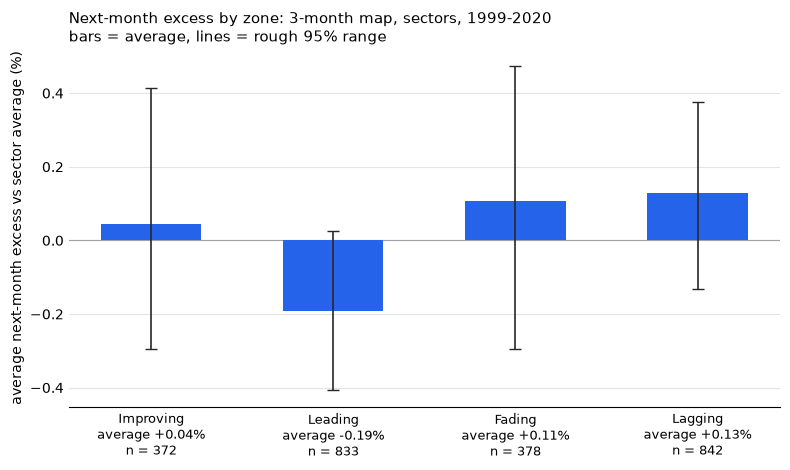

In [8]:
z = t1[t1.zone.isin(ZONES)].set_index("zone").reindex(ZONES)
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(ZONES))
yerr = np.vstack([z.avg_excess_pct - z.range95_low_pct, z.range95_high_pct - z.avg_excess_pct])
ax.bar(x, z.avg_excess_pct, width=0.55, color="#2563eb", zorder=2)
ax.errorbar(x, z.avg_excess_pct, yerr=yerr, fmt="none", ecolor="#27272a", elinewidth=1.2, capsize=4, zorder=3)
ax.axhline(0, color="#a1a1aa", lw=0.8, zorder=1)
ax.set_xticks(x); ax.set_xticklabels([f"{zn}\naverage {a:+.2f}%\nn = {int(c):,}" for zn, a, c in zip(ZONES, z.avg_excess_pct, z["count"])], fontsize=9.5)
ax.set_ylabel("average next-month excess vs sector average (%)")
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Next-month excess by zone: 3-month map, sectors, 1999-2020\nbars = average, lines = rough 95% range", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(R / "04_avg_excess_by_zone.png", dpi=150); plt.show()

## 8. Checks for the three Part A predictions

In [9]:
zz = t1.set_index("zone")
imp, lead, fad = zz.loc["Improving", "avg_excess_pct"], zz.loc["Leading", "avg_excess_pct"], zz.loc["Fading", "avg_excess_pct"]
print(f"Z1: Improving average {imp:+.3f}% per month (need > 0) and Leading {lead:+.3f}% (Improving must be higher) -> {'CONFIRMED' if (imp > 0 and imp > lead) else 'CONTRADICTED'}")
print(f"    Improving range {zz.loc['Improving','range95_low_pct']:+.3f}% to {zz.loc['Improving','range95_high_pct']:+.3f}% | Leading range {zz.loc['Leading','range95_low_pct']:+.3f}% to {zz.loc['Leading','range95_high_pct']:+.3f}%")
print(f"Z2: Fading average {fad:+.3f}% per month (need < 0) -> {'CONFIRMED' if fad < 0 else 'CONTRADICTED'}   range {zz.loc['Fading','range95_low_pct']:+.3f}% to {zz.loc['Fading','range95_high_pct']:+.3f}%")
cwn, ccwn = int((mv.move == "clockwise (one step)").sum()), int((mv.move == "counter-clockwise (one step)").sum())
print(f"Z3: clockwise {cwn} vs counter-clockwise {ccwn} one-step moves (need clockwise > counter-clockwise) -> {'CONFIRMED' if cwn > ccwn else 'CONTRADICTED'}")
print(f"    (two-step jumps: {int((mv.move == 'two-step jump').sum())}; stayed: {int((mv.move == 'stayed').sum())})")

Z1: Improving average +0.044% per month (need > 0) and Leading -0.193% (Improving must be higher) -> CONFIRMED
    Improving range -0.296% to +0.415% | Leading range -0.408% to +0.025%
Z2: Fading average +0.108% per month (need < 0) -> CONTRADICTED   range -0.295% to +0.474%
Z3: clockwise 831 vs counter-clockwise 353 one-step moves (need clockwise > counter-clockwise) -> CONFIRMED
    (two-step jumps: 372; stayed: 869)


## 9. Extra context (not a prediction): is the clockwise tendency just built into the zone rules?
Zones come from overlapping windows (the 21-day move is part of the 63-day move), which can make clockwise moves common even with no real pattern. To see how much, the trading days of the 9 sector funds that exist for the whole period are shuffled into random order (200 times, fixed seed), which removes any real pattern but keeps each day's cross-section of returns; zone moves are then recounted with the same rules and grid. The real data is recounted on the same 9 funds for a fair comparison.

In [10]:
core = [s for s in SECT if P[s].notna().all()]
def move_counts(Pc):
    ch = lambda k: Pc / Pc.shift(k) - 1
    ex63 = ch(63).sub(ch(63).mean(axis=1), axis=0).iloc[checks].values
    ex21 = ch(21).sub(ch(21).mean(axis=1), axis=0).iloc[checks].values
    zc = np.where(ex63 >= 0, np.where(ex21 >= 0, 1, 2), np.where(ex21 >= 0, 0, 3))      # Improving 0, Leading 1, Fading 2, Lagging 3 (clockwise = +1)
    d = (zc[1:] - zc[:-1]) % 4
    return dict(stayed=int((d == 0).sum()), cw=int((d == 1).sum()), ccw=int((d == 3).sum()), two_step=int((d == 2).sum()))
real = move_counts(P[core])
rets = P[core].pct_change().iloc[1:].values
rng = np.random.default_rng(0)
null = []
for _ in range(200):
    r = rets[rng.permutation(len(rets))]
    Ps = pd.DataFrame(np.vstack([np.ones((1, len(core))), np.cumprod(1 + r, axis=0)]), index=P.index, columns=core)
    null.append(move_counts(Ps))
null = pd.DataFrame(null)
null["cw_share_of_one_step"] = null.cw / (null.cw + null.ccw) * 100
real_share = real["cw"] / (real["cw"] + real["ccw"]) * 100
res = pd.DataFrame({"real (9 core funds)": {**real, "cw_share_of_one_step": real_share},
                    "shuffled days: average": null.mean(), "shuffled days: 2.5th pct": null.quantile(0.025), "shuffled days: 97.5th pct": null.quantile(0.975)}).T
res.round(1).to_csv(R / "04_zone_move_shuffle_check.csv")
print("9 core funds:", core); print(res.round(1).to_string())

9 core funds: ['XLK', 'XLE', 'XLV', 'XLU', 'XLF', 'XLI', 'XLB', 'XLP', 'XLY']
                           stayed     cw    ccw  two_step  cw_share_of_one_step
real (9 core funds)         860.0  802.0  328.0     350.0                  71.0
shuffled days: average      889.4  779.9  319.9     350.8                  70.9
shuffled days: 2.5th pct    841.0  741.0  292.0     316.0                  68.7
shuffled days: 97.5th pct   945.0  820.1  348.1     392.3                  73.0
